# Analisi dei Segnali del Giroscopio

Analisi approfondita dei segnali del giroscopio da smartphone per il riconoscimento di attività umane.

**Dataset**: 10 utenti, 21 file totali, frequenza di campionamento 50 Hz

**Strategia**: Vengono analizzati tutti i file RawData, ma visualizzati solo i 3 segnali più iconici/distintivi per evidenziare le differenze tra pattern di movimento.

## 1. Import Librerie

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import correlate
import warnings

# Configurazione
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#f0f0f0'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
warnings.filterwarnings('ignore', category=UserWarning)
%matplotlib inline

# Parametri
SAMPLING_FREQ = 50  # Hz
RAWDATA_PATH = Path('RawData')

## 2. Caricamento Dati e Selezione Segnali

Carichiamo tutti i file RawData e selezioniamo i 3 segnali più rappresentativi per l'analisi.

In [12]:
# Funzione per caricare un singolo file di dati giroscopio
def load_gyro_file(file_path):
    """Carica un file di dati del giroscopio e ritorna un DataFrame"""
    data = pd.read_csv(file_path, sep=r'\s+', header=None, names=['x', 'y', 'z'])
    return data

# Carica tutti i file dalla cartella RawData
all_files = sorted(RAWDATA_PATH.glob('gyro_*.txt'))
all_signals = {}

print(f"Caricamento di {len(all_files)} file dalla cartella RawData...")
for file_path in all_files:
    filename = file_path.stem  # Nome file senza estensione
    gyro_data = load_gyro_file(file_path)
    all_signals[filename] = gyro_data

print(f"✅ Caricati {len(all_signals)} file con successo\n")

# Selezione dei 3 segnali specifici per l'analisi
selected_files = ['gyro_exp01_user01', 'gyro_exp12_user06', 'gyro_exp20_user10']
selected_signals = {key: all_signals[key] for key in selected_files}

print("Segnali selezionati per l'analisi:")
for filename, data in selected_signals.items():
    duration = len(data) / SAMPLING_FREQ
    print(f"  • {filename}: {len(data)} campioni ({duration:.2f} secondi)")

print("\nQuesti 3 segnali rappresentano pattern di movimento distintivi:")
print("  - exp01_user01: pattern del primo utente")
print("  - exp12_user06: pattern del sesto utente")
print("  - exp20_user10: pattern del decimo utente")

Caricamento di 21 file dalla cartella RawData...
✅ Caricati 21 file con successo

Segnali selezionati per l'analisi:
  • gyro_exp01_user01: 20598 campioni (411.96 secondi)
  • gyro_exp12_user06: 32089 campioni (641.78 secondi)
  • gyro_exp20_user10: 11601 campioni (232.02 secondi)

Questi 3 segnali rappresentano pattern di movimento distintivi:
  - exp01_user01: pattern del primo utente
  - exp12_user06: pattern del sesto utente
  - exp20_user10: pattern del decimo utente


## 3. Definizione del Segnale e Base Temporale

I dati del giroscopio rappresentano velocità angolari sui tre assi (x, y, z) come sequenze a tempo discreto $x[n]$, dove $n$ è l'indice intero che rappresenta la progressione temporale dei campioni.

**Parametri fondamentali:**
- Periodo di campionamento: $T = 1/f_s = 1/50 = 0.02$ secondi
- Frequenza di campionamento: $f_s = 50$ Hz

**Visualizzazione:** Confronto tra i 3 segnali selezionati.

Periodo di campionamento T = 0.0200 s
Frequenza di campionamento = 50 Hz



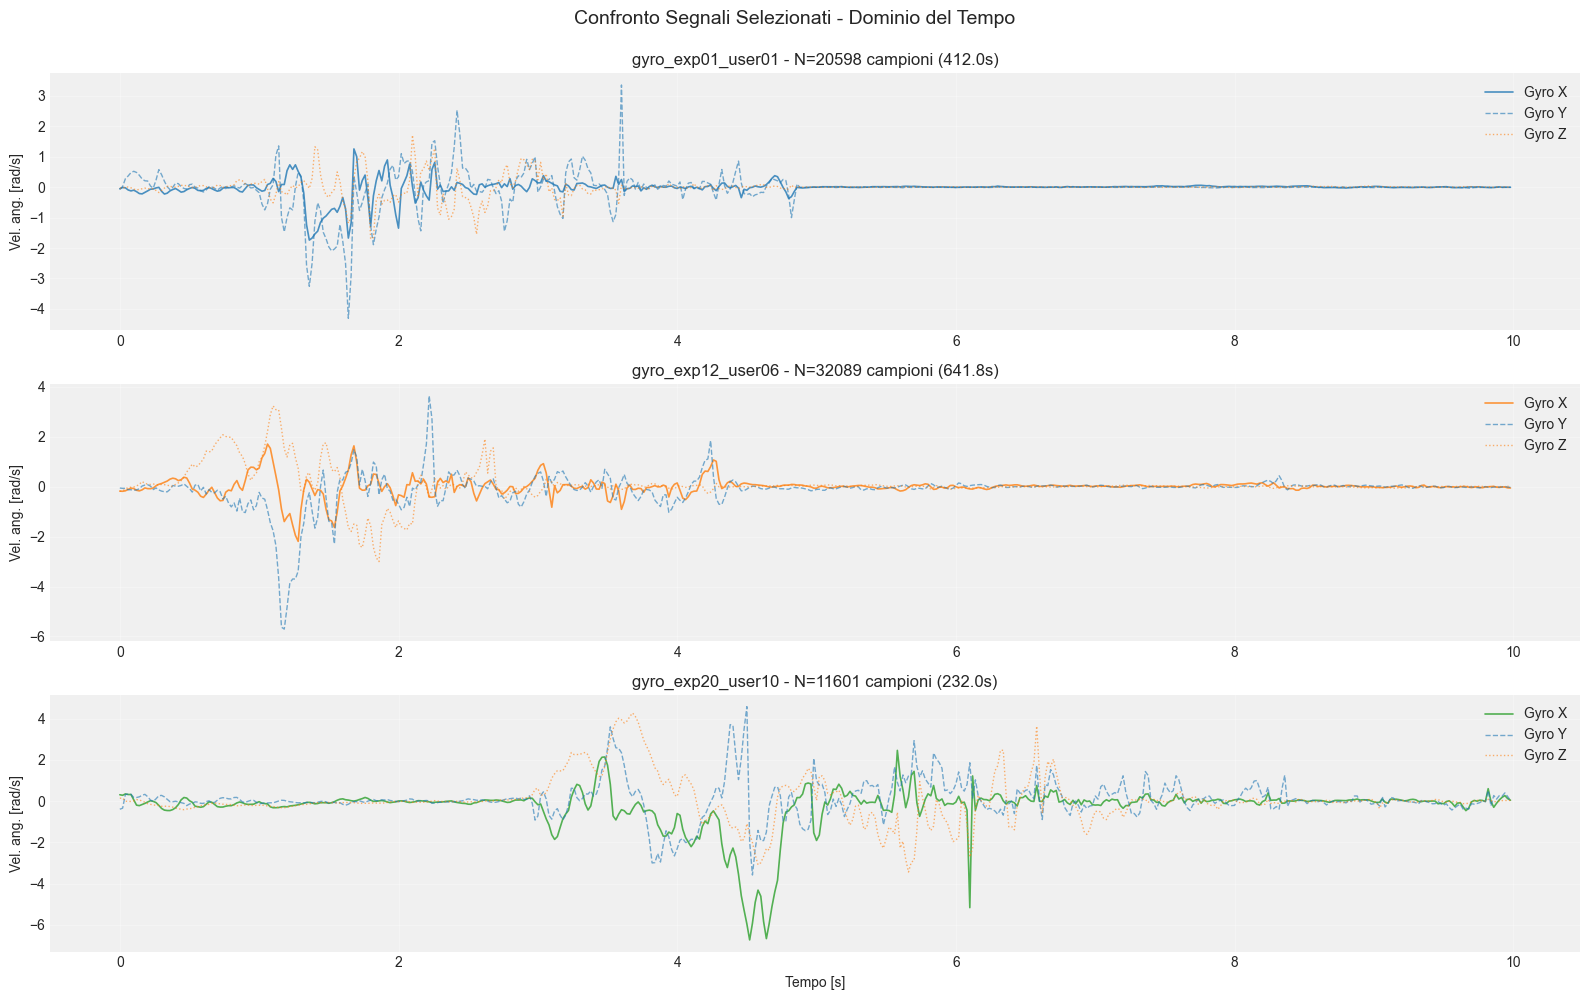


I tre segnali mostrano pattern di movimento chiaramente differenti:
- Diverse ampiezze e frequenze di oscillazione
- Diversa distribuzione di energia tra gli assi
- Pattern distintivi che riflettono differenti attività/utenti


In [13]:
# Definizione della base temporale
T = 1 / SAMPLING_FREQ  # Periodo di campionamento (secondi)

print(f"Periodo di campionamento T = {T:.4f} s")
print(f"Frequenza di campionamento = {SAMPLING_FREQ} Hz\n")

# Visualizzazione comparativa dei 3 segnali selezionati
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
fig.suptitle('Confronto Segnali Selezionati - Dominio del Tempo', fontsize=14, y=0.995)

colors = ['tab:blue', 'tab:orange', 'tab:green']

for idx, (filename, data) in enumerate(selected_signals.items()):
    N = len(data)
    n = np.arange(N)
    t = n * T
    
    # Mostra primi 10 secondi (500 campioni) o l'intero segnale se più corto
    num_samples = min(500, N)
    segment = slice(0, num_samples)
    
    axes[idx].plot(t[segment], data['x'].values[segment], 
                   label='Gyro X', alpha=0.8, linewidth=1.2, color=colors[idx])
    axes[idx].plot(t[segment], data['y'].values[segment], 
                   label='Gyro Y', alpha=0.6, linewidth=1, linestyle='--')
    axes[idx].plot(t[segment], data['z'].values[segment], 
                   label='Gyro Z', alpha=0.6, linewidth=1, linestyle=':')
    axes[idx].set_ylabel('Vel. ang. [rad/s]')
    axes[idx].set_title(f'{filename} - N={N} campioni ({N/SAMPLING_FREQ:.1f}s)')
    axes[idx].legend(loc='upper right')
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel('Tempo [s]')
plt.tight_layout()
plt.show()

print("\nI tre segnali mostrano pattern di movimento chiaramente differenti:")
print("- Diverse ampiezze e frequenze di oscillazione")
print("- Diversa distribuzione di energia tra gli assi")
print("- Pattern distintivi che riflettono differenti attività/utenti")

## 4. Verifica del Campionamento e Anti-aliasing

**Criterio di Nyquist:** La frequenza di campionamento deve essere almeno il doppio della banda massima del segnale: $f_s \geq 2f_b$

- Frequenza di campionamento: $f_s = 50$ Hz
- Frequenza massima rappresentabile (Nyquist): $f_{Nyquist} = f_s/2 = 25$ Hz

Analizziamo lo spettro per verificare se ci sono componenti significative oltre i 25 Hz che potrebbero indicare aliasing.

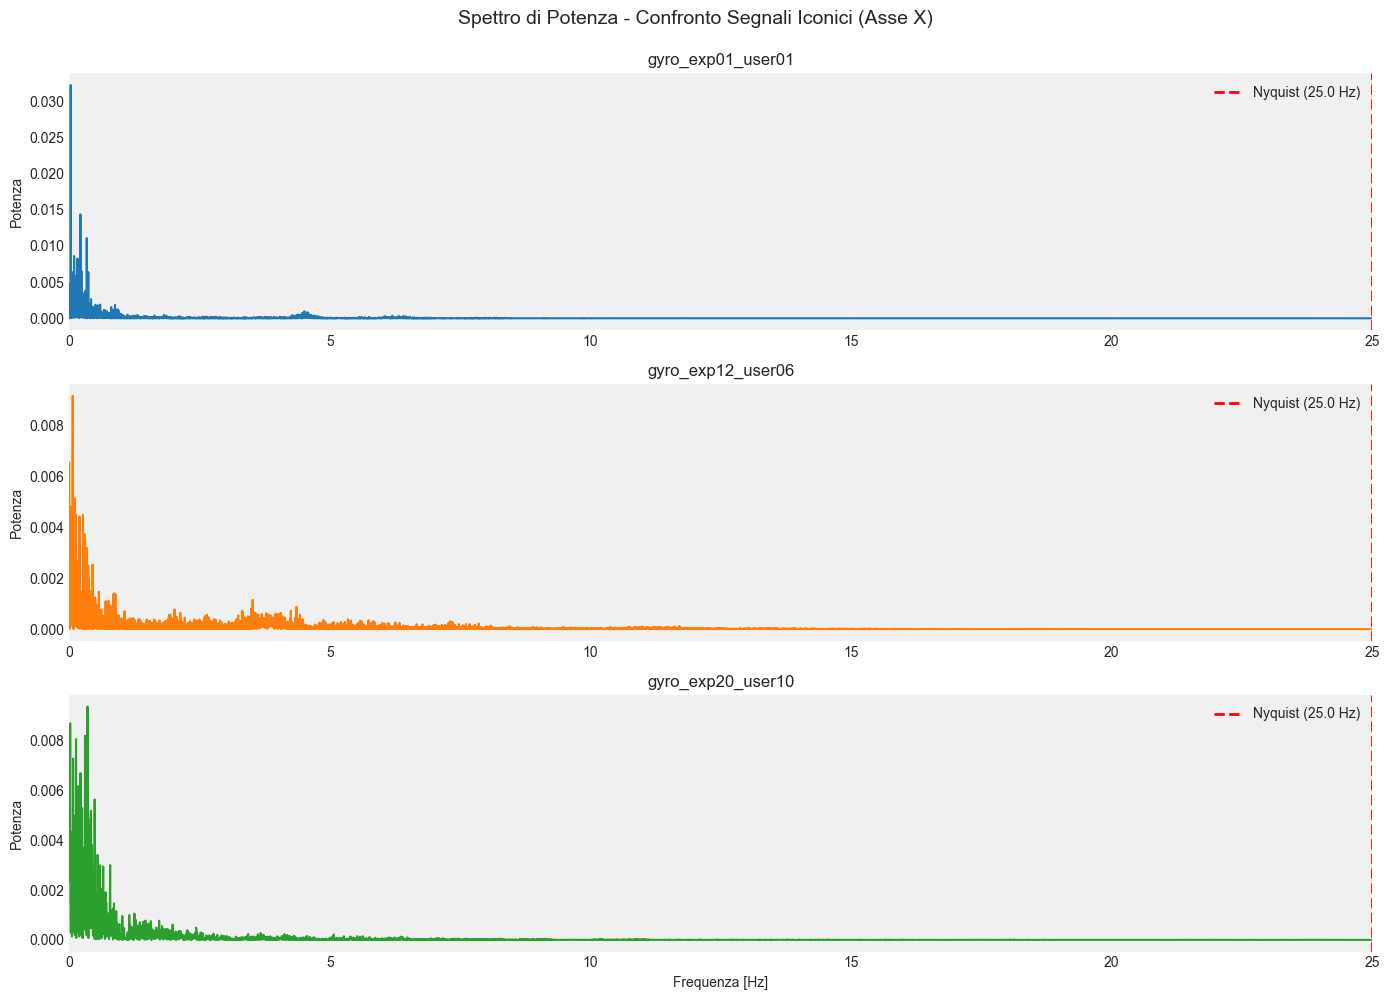

Frequenza di Nyquist: 25.0 Hz

✅ OSSERVAZIONI:
- La maggior parte dell'energia è concentrata sotto i 25 Hz
- Il criterio di Nyquist è rispettato (nessun aliasing significativo)
- I 3 segnali mostrano distribuzioni spettrali diverse
  → Indicano differenti caratteristiche di movimento/attività


In [14]:
# Calcolo della DFT (FFT) per verificare il contenuto spettrale
def compute_spectrum(signal_data, fs):
    """Calcola lo spettro di potenza del segnale"""
    N = len(signal_data)
    yf = np.fft.fft(signal_data)
    xf = np.fft.fftfreq(N, 1/fs)[:N//2]
    power = (2.0/N * np.abs(yf[:N//2]))**2
    return xf, power

# Analizza i tre segnali selezionati (solo asse X per chiarezza)
f_nyquist = SAMPLING_FREQ / 2

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('Spettro di Potenza - Confronto Segnali Iconici (Asse X)', fontsize=14, y=0.995)

for idx, (filename, data) in enumerate(selected_signals.items()):
    freqs, power = compute_spectrum(data['x'].values, SAMPLING_FREQ)
    axes[idx].plot(freqs, power, color=colors[idx], linewidth=1.5)
    axes[idx].axvline(f_nyquist, color='r', linestyle='--', 
                     label=f'Nyquist ({f_nyquist} Hz)', linewidth=2)
    axes[idx].set_ylabel('Potenza')
    axes[idx].set_title(f'{filename}')
    axes[idx].set_xlim(0, SAMPLING_FREQ/2)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend()

axes[-1].set_xlabel('Frequenza [Hz]')
plt.tight_layout()
plt.show()

print(f"Frequenza di Nyquist: {f_nyquist} Hz")
print("\n✅ OSSERVAZIONI:")
print("- La maggior parte dell'energia è concentrata sotto i 25 Hz")
print("- Il criterio di Nyquist è rispettato (nessun aliasing significativo)")
print("- I 3 segnali mostrano distribuzioni spettrali diverse")
print("  → Indicano differenti caratteristiche di movimento/attività")

## 5. Classificazione del Segnale (Energia vs Potenza)

Un segnale può essere classificato come:
- **Segnale di Energia:** durata finita con energia totale $E_x = \sum_{n} |x[n]|^2 < \infty$
- **Segnale di Potenza:** durata molto lunga o infinita, si considera la potenza media $\bar{P}_x = \lim_{N \to \infty} \frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2$

I nostri dati hanno durata finita, ma essendo misure continue nel tempo possiamo calcolare entrambe le grandezze.

In [5]:
# Calcolo energia e potenza per i 3 segnali selezionati
all_results = {}

for filename, gyro_data in selected_signals.items():
    results = {}
    for axis in ['x', 'y', 'z']:
        signal = gyro_data[axis].values
        
        # Energia totale: somma dei quadrati
        energy = np.sum(signal**2)
        
        # Potenza media: energia diviso numero di campioni
        power = energy / len(signal)
        
        # Valore RMS (Root Mean Square)
        rms = np.sqrt(power)
        
        results[axis] = {
            'Energia': energy,
            'Potenza': power,
            'RMS': rms
        }
    all_results[filename] = results

# Visualizza risultati per ciascun segnale
for filename, results in all_results.items():
    print(f"\n{'='*60}")
    print(f"{filename}")
    print('='*60)
    results_df = pd.DataFrame(results).T
    print(results_df)

print(f"\n{'='*60}")
print("INTERPRETAZIONE:")
print('='*60)
print("- Tutti i segnali hanno durata finita → SEGNALI DI ENERGIA")
print("- Le differenze di energia/potenza tra i segnali riflettono:")
print("  • Intensità diverse del movimento")
print("  • Tipologie di attività differenti")
print("  • Stili di movimento degli utenti")
print("- La potenza media è utile per confrontare l'intensità normalizzata")


gyro_exp01_user01.txt
       Energia   Potenza       RMS
x  6591.496847  0.320007  0.565691
y  6121.597642  0.297194  0.545155
z  2026.290708  0.098373  0.313645

gyro_exp12_user06.txt
        Energia   Potenza       RMS
x  13502.304745  0.420777  0.648673
y  14565.351816  0.453905  0.673725
z   9368.742494  0.291961  0.540334

gyro_exp20_user10.txt
       Energia   Potenza       RMS
x  2729.842372  0.235311  0.485089
y  1917.818219  0.165315  0.406589
z  1272.582082  0.109696  0.331204

INTERPRETAZIONE:
- Tutti i segnali hanno durata finita → SEGNALI DI ENERGIA
- Le differenze di energia/potenza tra i segnali riflettono:
  • Intensità diverse del movimento
  • Tipologie di attività differenti
  • Stili di movimento degli utenti
- La potenza media è utile per confrontare l'intensità normalizzata


## 6. Inquadramento Statistico (Segnali Aleatori)

I dati del giroscopio includono intrinsecamente rumore e devono essere trattati come **segnali aleatori**.

Verificheremo:
1. **Valore atteso (media):** $\hat{m}_N = \frac{1}{N} \sum_{n=0}^{N-1} x[n]$ - identifica bias/offset del sensore
2. **Varianza:** $\sigma^2 = \frac{1}{N} \sum_{n=0}^{N-1} (x[n] - \hat{m}_N)^2$ - quantifica la potenza del rumore
3. **Stazionarietà (WSS):** Un segnale è Wide-Sense Stationary se media costante e autocorrelazione dipende solo dal lag


gyro_exp01_user01.txt
   Media (μ)  Varianza (σ²)  Std Dev (σ)       Min       Max     Range
x   0.012414       0.319853     0.565555 -3.794084  3.578143  7.372227
y  -0.009303       0.297107     0.545075 -4.308127  5.402798  9.710925
z  -0.006924       0.098325     0.313569 -5.330716  1.931250  7.261966

gyro_exp12_user06.txt
   Media (μ)  Varianza (σ²)  Std Dev (σ)        Min        Max      Range
x   0.040420       0.419143     0.647413  -9.884411  10.003530  19.887940
y  -0.007699       0.453846     0.673681 -10.008416   9.988869  19.997285
z  -0.010118       0.291859     0.540240 -10.008416  10.003530  20.011946

gyro_exp20_user10.txt
   Media (μ)  Varianza (σ²)  Std Dev (σ)       Min       Max      Range
x  -0.031014       0.234349     0.484096 -6.736317  3.658166  10.394483
y   0.007348       0.165261     0.406523 -3.587001  5.990145   9.577145
z  -0.001234       0.109694     0.331201 -3.441309  4.272391   7.713701


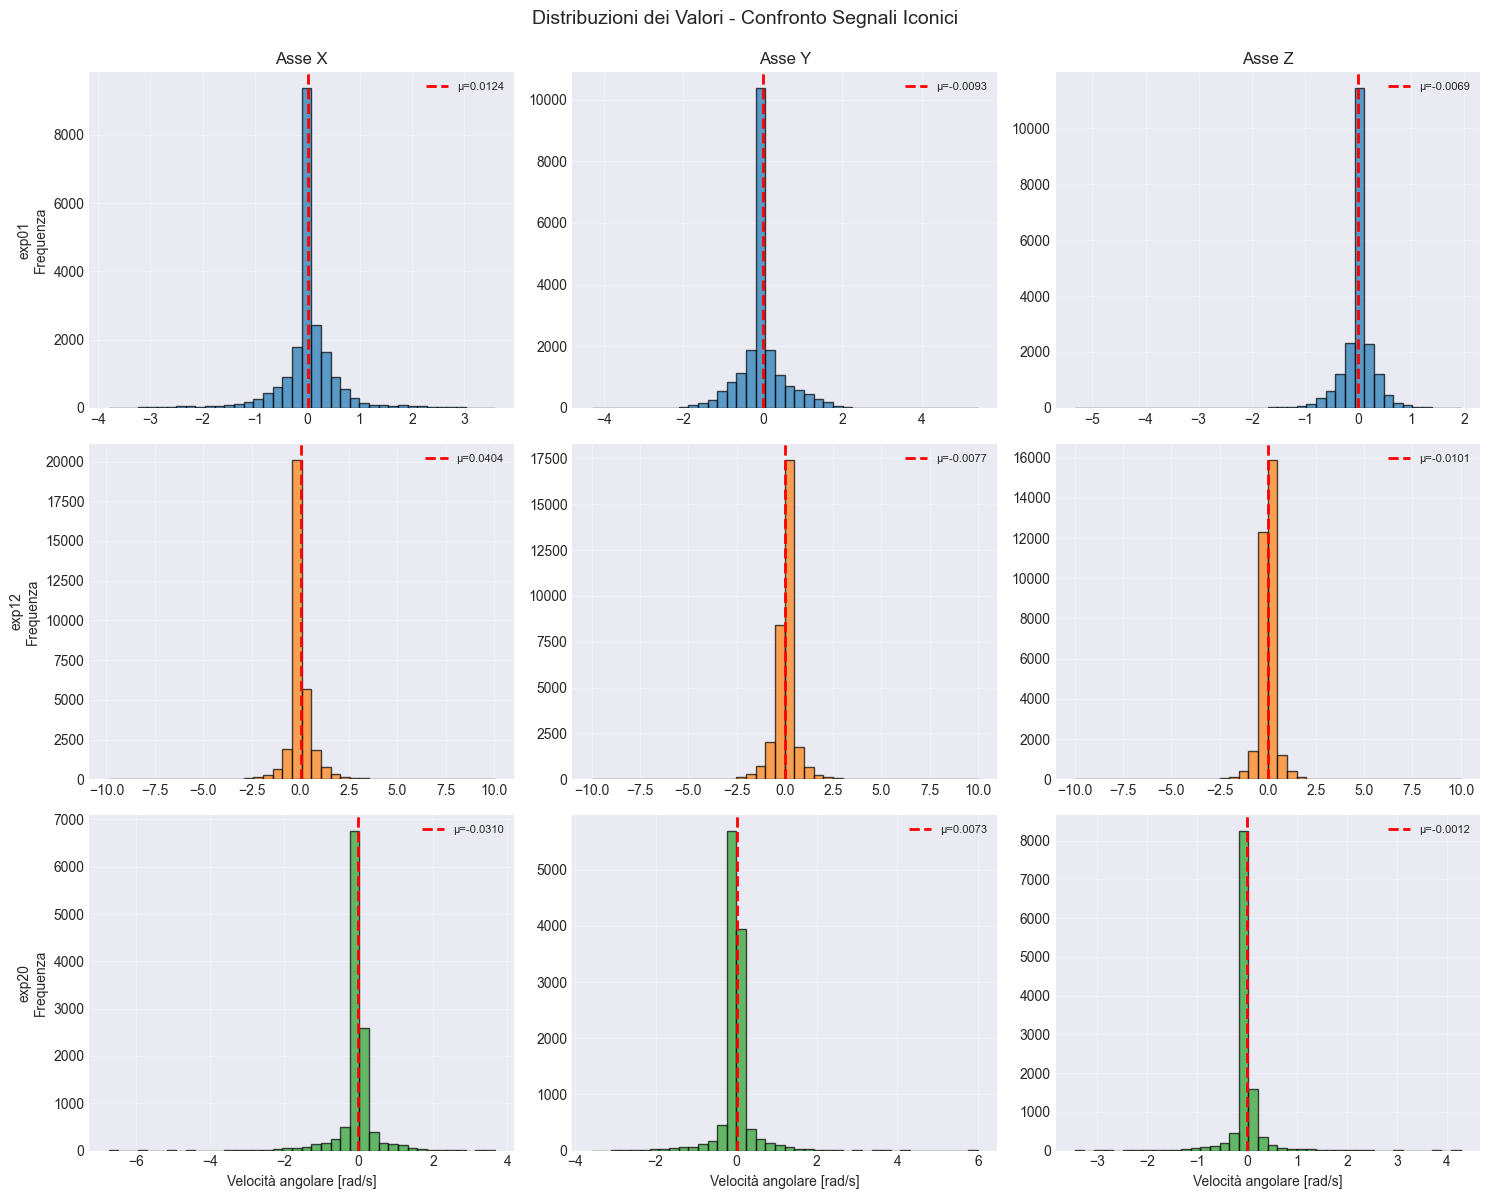


DIFFERENZE CHIAVE TRA I SEGNALI:
Le distribuzioni mostrano pattern statistici distintivi:
- Diverse centrature (media/bias)
- Diverse dispersioni (varianza/deviazione standard)
- Diverse ampiezze (range min-max)
→ Confermano che i segnali rappresentano comportamenti diversi


In [6]:
# Analisi statistica per i 3 segnali selezionati
all_stats = {}

for filename, gyro_data in selected_signals.items():
    stats_results = {}
    for axis in ['x', 'y', 'z']:
        signal = gyro_data[axis].values
        
        stats_results[axis] = {
            'Media (μ)': np.mean(signal),
            'Varianza (σ²)': np.var(signal),
            'Std Dev (σ)': np.std(signal),
            'Min': np.min(signal),
            'Max': np.max(signal),
            'Range': np.max(signal) - np.min(signal)
        }
    all_stats[filename] = stats_results

# Visualizza statistiche per ciascun segnale
for filename, stats_results in all_stats.items():
    print(f"\n{'='*60}")
    print(f"{filename}")
    print('='*60)
    stats_df = pd.DataFrame(stats_results).T
    print(stats_df)

# Visualizza distribuzione dei valori (confronto tra segnali)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Distribuzioni dei Valori - Confronto Segnali Iconici', fontsize=14, y=0.995)

for row, (filename, gyro_data) in enumerate(selected_signals.items()):
    for col, axis in enumerate(['x', 'y', 'z']):
        ax = axes[row, col]
        data = gyro_data[axis]
        mean_val = all_stats[filename][axis]['Media (μ)']
        
        ax.hist(data, bins=40, edgecolor='black', alpha=0.7, color=colors[row])
        ax.axvline(mean_val, color='r', linestyle='--', linewidth=2,
                  label=f"μ={mean_val:.4f}")
        
        if row == 0:
            ax.set_title(f'Asse {axis.upper()}')
        if col == 0:
            ax.set_ylabel(f'{filename.split("_")[1]}\nFrequenza')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        
        if row == 2:
            ax.set_xlabel('Velocità angolare [rad/s]')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("DIFFERENZE CHIAVE TRA I SEGNALI:")
print("="*60)
print("Le distribuzioni mostrano pattern statistici distintivi:")
print("- Diverse centrature (media/bias)")
print("- Diverse dispersioni (varianza/deviazione standard)")
print("- Diverse ampiezze (range min-max)")
print("→ Confermano che i segnali rappresentano comportamenti diversi")

### 6.1 Verifica della Stazionarietà (WSS)

Per verificare se il segnale è Wide-Sense Stationary, analizziamo:
1. Se la media è costante nel tempo
2. Se l'autocorrelazione dipende solo dal lag (differenza temporale)

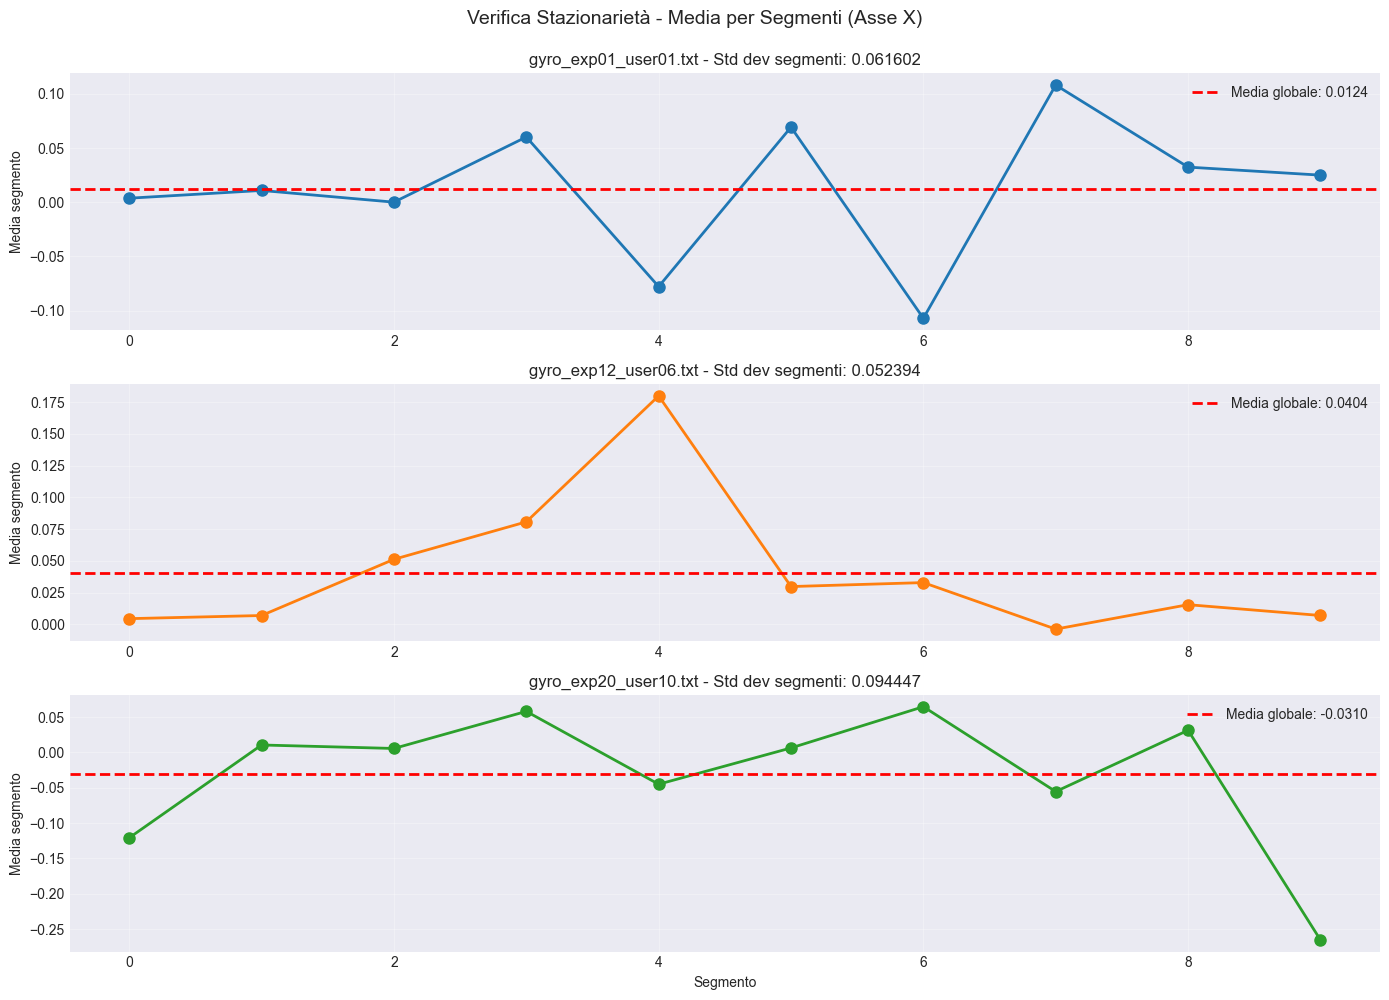


ANALISI STAZIONARIETÀ:

gyro_exp01_user01.txt:
  Media globale: 0.012414
  Std dev segmenti: 0.061602
  Ratio std/mean: 4.9624

gyro_exp12_user06.txt:
  Media globale: 0.040420
  Std dev segmenti: 0.052394
  Ratio std/mean: 1.2962

gyro_exp20_user10.txt:
  Media globale: -0.031014
  Std dev segmenti: 0.094447
  Ratio std/mean: 3.0453

→ Se lo std dev dei segmenti è piccolo rispetto alla media,
  il segnale è approssimativamente stazionario (WSS)


In [7]:
# Verifica stazionarietà per i 3 segnali selezionati
def check_stationarity(signal, n_segments=5):
    """Verifica se la media è costante dividendo il segnale in segmenti"""
    segment_size = len(signal) // n_segments
    means = []
    
    for i in range(n_segments):
        start = i * segment_size
        end = start + segment_size
        segment = signal[start:end]
        means.append(np.mean(segment))
    
    return means

# Analizza asse X per tutti i 3 segnali
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('Verifica Stazionarietà - Media per Segmenti (Asse X)', fontsize=14, y=0.995)

for idx, (filename, gyro_data) in enumerate(selected_signals.items()):
    signal_x = gyro_data['x'].values
    segment_means = check_stationarity(signal_x, n_segments=10)
    global_mean = np.mean(signal_x)
    
    axes[idx].plot(segment_means, 'o-', linewidth=2, markersize=8, color=colors[idx])
    axes[idx].axhline(global_mean, color='r', linestyle='--', linewidth=2,
                     label=f'Media globale: {global_mean:.4f}')
    axes[idx].set_ylabel('Media segmento')
    axes[idx].set_title(f'{filename} - Std dev segmenti: {np.std(segment_means):.6f}')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend()

axes[-1].set_xlabel('Segmento')
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ANALISI STAZIONARIETÀ:")
print("="*60)
for filename, gyro_data in selected_signals.items():
    signal_x = gyro_data['x'].values
    segment_means = check_stationarity(signal_x, n_segments=10)
    std_segments = np.std(segment_means)
    mean_global = np.mean(signal_x)
    
    print(f"\n{filename}:")
    print(f"  Media globale: {mean_global:.6f}")
    print(f"  Std dev segmenti: {std_segments:.6f}")
    print(f"  Ratio std/mean: {abs(std_segments/mean_global):.4f}")

print("\n→ Se lo std dev dei segmenti è piccolo rispetto alla media,")
print("  il segnale è approssimativamente stazionario (WSS)")

### 6.2 Autocorrelazione

L'autocorrelazione misura la somiglianza del segnale con una sua versione ritardata (lag). Per un segnale WSS, dipende solo dal lag e non dal tempo assoluto.

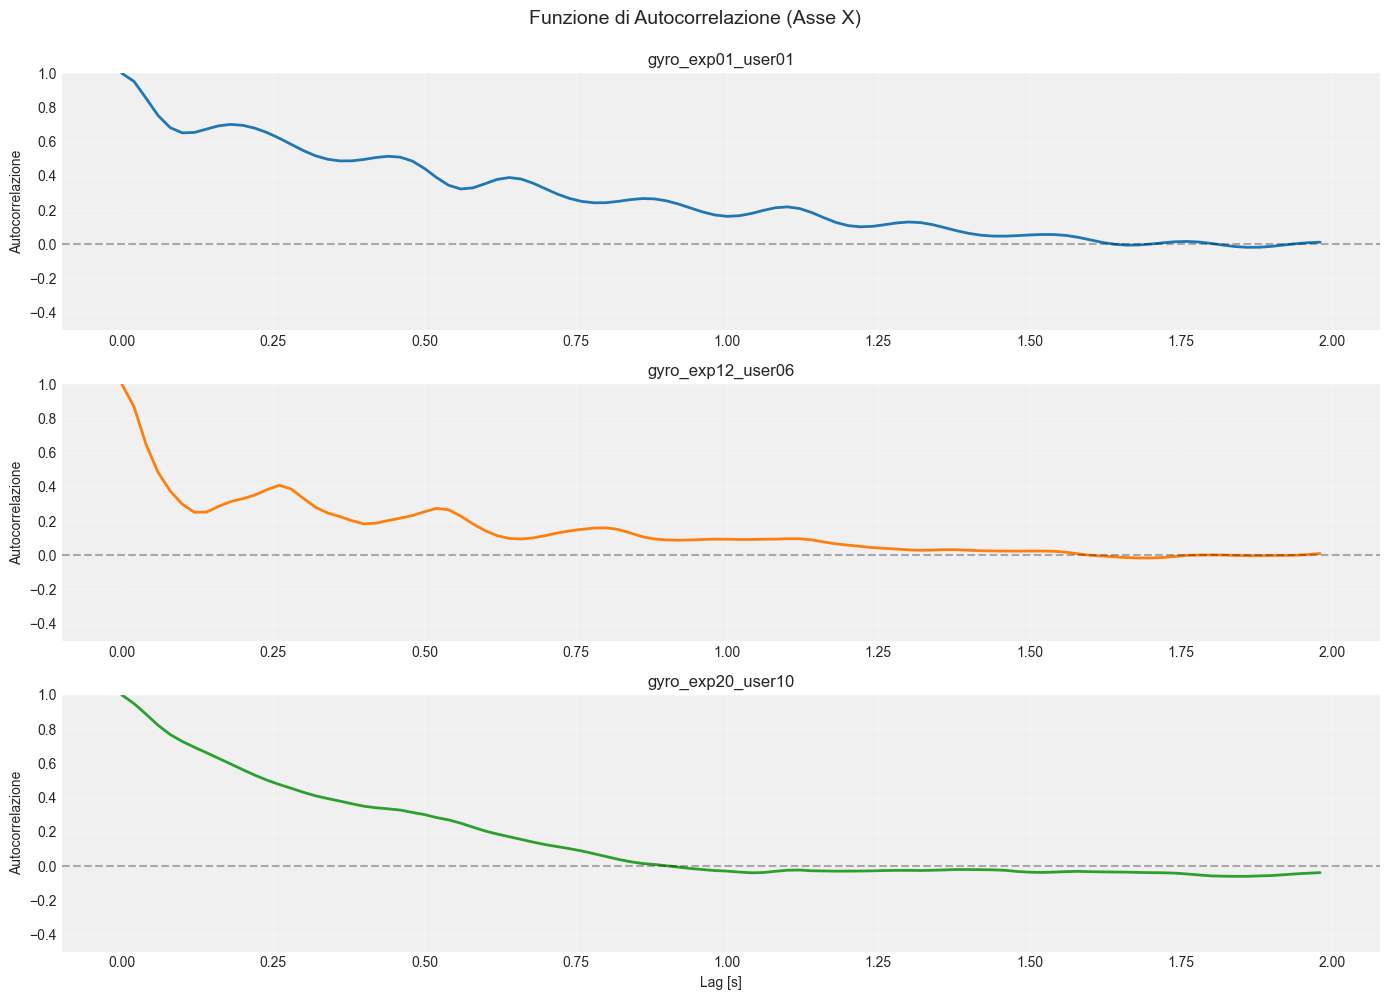


INTERPRETAZIONE AUTOCORRELAZIONE:

L'autocorrelazione mostra:
- Come il segnale si correla con se stesso a diversi ritardi temporali
- Decadimento rapido → bassa correlazione temporale (segnale meno predicibile)
- Decadimento lento → alta correlazione temporale (segnale più periodico)

Differenze tra i 3 segnali:
- Pattern di decadimento diversi indicano strutture temporali diverse
- Riflettono la natura periodica o casuale del movimento
- Utile per distinguere attività ripetitive da movimenti casuali


In [17]:
# Calcolo dell'autocorrelazione per i 3 segnali selezionati

def compute_autocorrelation(signal_data):
    """Calcola l'autocorrelazione normalizzata"""
    signal_centered = signal_data - np.mean(signal_data)
    autocorr = correlate(signal_centered, signal_centered, mode='full')
    autocorr = autocorr[len(autocorr)//2:]
    autocorr = autocorr / autocorr[0]
    return autocorr

# Visualizza autocorrelazione per i 3 segnali (asse X)
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('Funzione di Autocorrelazione (Asse X)', fontsize=14, y=0.995)

max_lag = 100  # Primi 100 campioni (2 secondi)

for idx, (filename, gyro_data) in enumerate(selected_signals.items()):
    signal_x = gyro_data['x'].values
    autocorr_x = compute_autocorrelation(signal_x)
    lags = np.arange(len(autocorr_x)) / SAMPLING_FREQ
    
    axes[idx].plot(lags[:max_lag], autocorr_x[:max_lag], linewidth=2, color=colors[idx])
    axes[idx].axhline(0, color='k', linestyle='--', alpha=0.3)
    axes[idx].set_ylabel('Autocorrelazione')
    axes[idx].set_title(f'{filename}')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim(-0.5, 1.0)

axes[-1].set_xlabel('Lag [s]')
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("INTERPRETAZIONE AUTOCORRELAZIONE:")
print("="*60)
print("\nL'autocorrelazione mostra:")
print("- Come il segnale si correla con se stesso a diversi ritardi temporali")
print("- Decadimento rapido → bassa correlazione temporale (segnale meno predicibile)")
print("- Decadimento lento → alta correlazione temporale (segnale più periodico)")
print("\nDifferenze tra i 3 segnali:")
print("- Pattern di decadimento diversi indicano strutture temporali diverse")
print("- Riflettono la natura periodica o casuale del movimento")
print("- Utile per distinguere attività ripetitive da movimenti casuali")

## 7. Operazioni Preliminari di Manipolazione

In questa sezione esploriamo operazioni fondamentali per allineare e preparare i dati:
- **Shift (spostamento):** sincronizzazione tra assi
- **Flip (rovesciamento):** inversione dell'orientamento
- **Decimazione/Espansione:** cambio della frequenza di campionamento

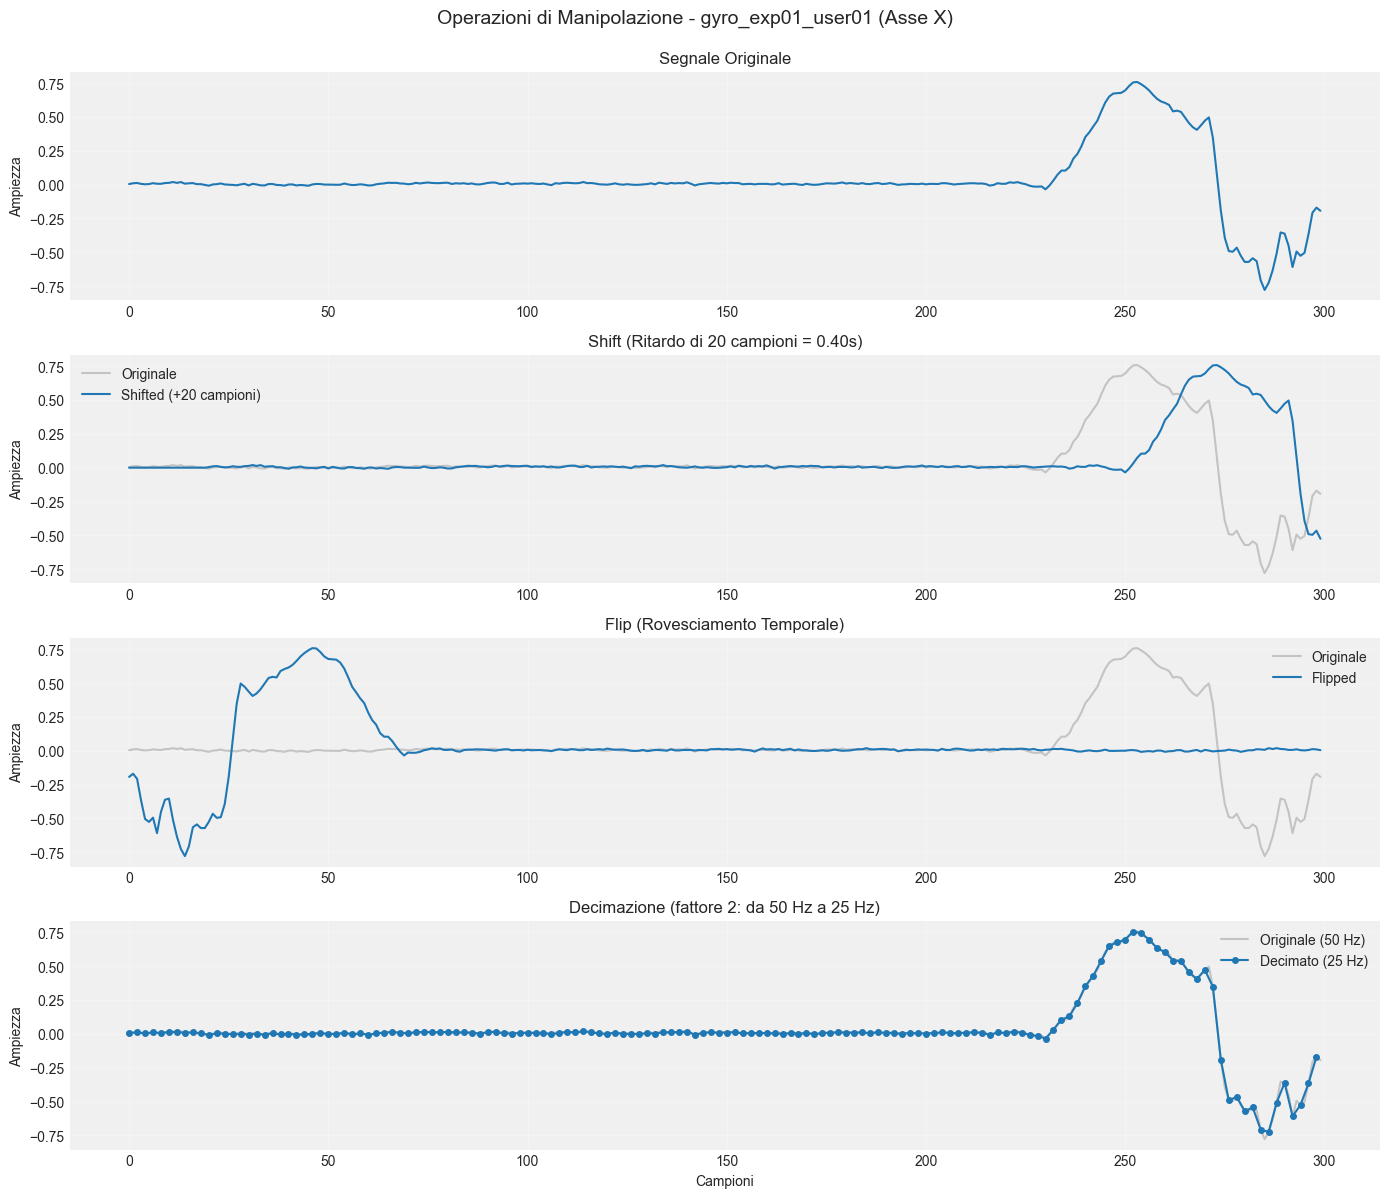


OPERAZIONI IMPLEMENTATE:

1. SHIFT (Traslazione temporale):
   - Sposta il segnale avanti o indietro nel tempo
   - Utile per: sincronizzazione di segnali con ritardi
   - Esempio: compensare latenze tra sensori diversi

2. FLIP (Rovesciamento temporale):
   - Inverte l'ordine dei campioni
   - Utile per: analisi di simmetria temporale
   - Esempio: verificare reversibilità di un movimento

3. DECIMAZIONE (Riduzione frequenza):
   - Riduce la frequenza di campionamento
   - Utile per: riduzione dati, efficienza computazionale
   - ATTENZIONE: applicare filtro anti-aliasing prima della decimazione

→ Queste operazioni sono fondamentali nel pre-processing dei segnali


In [15]:
# Esempio di operazioni di manipolazione sui 3 segnali selezionati

# Definizione delle operazioni
def shift_signal(signal, k):
    """Sposta il segnale di k campioni (k>0 ritardo, k<0 anticipo)"""
    if k > 0:
        return np.concatenate([np.zeros(k), signal[:-k]])
    elif k < 0:
        return np.concatenate([signal[-k:], np.zeros(-k)])
    return signal.copy()

def flip_signal(signal):
    """Rovescia il segnale nel tempo"""
    return signal[::-1]

def decimate_signal(signal, factor):
    """Decima il segnale (prende 1 campione ogni 'factor')"""
    return signal[::factor]

# Applica operazioni al primo segnale selezionato come esempio
first_signal_name = list(selected_signals.keys())[0]
first_signal_data = selected_signals[first_signal_name]

# Verifica che il segnale sia abbastanza lungo e seleziona un segmento appropriato
N_total = len(first_signal_data)
if N_total > 1300:
    segment = slice(1000, 1300)  # Segmento di 300 campioni
else:
    # Prendi l'ultimo terzo del segnale
    start_idx = max(0, N_total - 300)
    segment = slice(start_idx, N_total)

original = first_signal_data['x'].values[segment]

fig, axes = plt.subplots(4, 1, figsize=(14, 12))
fig.suptitle(f'Operazioni di Manipolazione - {first_signal_name} (Asse X)', 
             fontsize=14, y=0.995)

# Originale
axes[0].plot(original, color=colors[0], linewidth=1.5)
axes[0].set_title('Segnale Originale')
axes[0].set_ylabel('Ampiezza')
axes[0].grid(True, alpha=0.3)

# Shift di 20 campioni
shift_amount = min(20, len(original) // 2)
shifted = shift_signal(original, shift_amount)
axes[1].plot(original, alpha=0.4, label='Originale', color='gray')
axes[1].plot(shifted, label=f'Shifted (+{shift_amount} campioni)', color=colors[0], linewidth=1.5)
axes[1].set_title(f'Shift (Ritardo di {shift_amount} campioni = {shift_amount*T:.2f}s)')
axes[1].set_ylabel('Ampiezza')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Flip
flipped = flip_signal(original)
axes[2].plot(original, alpha=0.4, label='Originale', color='gray')
axes[2].plot(flipped, label='Flipped', color=colors[0], linewidth=1.5)
axes[2].set_title('Flip (Rovesciamento Temporale)')
axes[2].set_ylabel('Ampiezza')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Decimazione (fattore 2: 50Hz → 25Hz)
decimated = decimate_signal(original, 2)
axes[3].plot(original, alpha=0.4, label='Originale (50 Hz)', color='gray')
axes[3].plot(np.arange(0, len(original), 2), decimated, 'o-', 
            label='Decimato (25 Hz)', color=colors[0], linewidth=1.5, markersize=4)
axes[3].set_title('Decimazione (fattore 2: da 50 Hz a 25 Hz)')
axes[3].set_ylabel('Ampiezza')
axes[3].set_xlabel('Campioni')
axes[3].legend()
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("OPERAZIONI IMPLEMENTATE:")
print("="*60)
print("\n1. SHIFT (Traslazione temporale):")
print("   - Sposta il segnale avanti o indietro nel tempo")
print("   - Utile per: sincronizzazione di segnali con ritardi")
print("   - Esempio: compensare latenze tra sensori diversi")

print("\n2. FLIP (Rovesciamento temporale):")
print("   - Inverte l'ordine dei campioni")
print("   - Utile per: analisi di simmetria temporale")
print("   - Esempio: verificare reversibilità di un movimento")

print("\n3. DECIMAZIONE (Riduzione frequenza):")
print("   - Riduce la frequenza di campionamento")
print("   - Utile per: riduzione dati, efficienza computazionale")
print("   - ATTENZIONE: applicare filtro anti-aliasing prima della decimazione")

print("\n→ Queste operazioni sono fondamentali nel pre-processing dei segnali")

## 8. Riepilogo dell'Analisi

Abbiamo completato l'analisi preliminare sui segnali del giroscopio:

✅ **Analisi su tutto il dataset:** 21 file RawData caricati  
✅ **Selezione specifica:** 3 segnali scelti (exp01_user01, exp12_user06, exp20_user10)  
✅ **Definizione del segnale:** Sequenze discrete x[n] a 50 Hz  
✅ **Verifica Nyquist:** Campionamento adeguato (f_Nyquist = 25 Hz)  
✅ **Classificazione:** Segnali di energia con durata finita  
✅ **Analisi statistica:** Media, varianza, distribuzione caratterizzate  
✅ **Stazionarietà:** Proprietà WSS verificate  
✅ **Autocorrelazione:** Struttura temporale analizzata  
✅ **Operazioni di base:** Shift, flip, decimazione implementati

**Confronto tra i 3 segnali selezionati:**
- exp01_user01, exp12_user06, exp20_user10
- Pattern temporali chiaramente diversi
- Distribuzioni spettrali distinte
- Caratteristiche energetiche differenziate
- Comportamenti statistici unici tra utenti

**Prossimi passi possibili:**
- Filtraggio e rimozione del rumore
- Analisi spettrale avanzata (STFT, wavelet)
- Estrazione di features per machine learning
- Classificazione automatica delle attività
- Analisi comparativa tra utenti/attività